# COU 07506 Digital Signal Processing
## Week 3 — Lab 1B: Convolution, Correlation and Difference Equations

**Name:** Deborah  
**Registration Number:** 240242455798  
**Class:** BEng24  
**Date:** 26 November 2026

---

## Pre-lab Preparation

### Question (a)
Convolve the sequences:

x(n) = {1, -1, 2}

h(n) = {2, 1, 0, 1}

### Solution

The linear convolution is:

y(n) = {2, -1, 3, 1, 2}

### Question (b)
Is the system y(n) = n x(n) time-invariant?

**Answer:**

No. The system is time-varying.

For an input x(n), the output is:

y(n) = n x(n)

If the input is delayed by n₀, the output becomes:

n x(n - n₀)

However, delaying the original output gives:

(n - n₀)x(n - n₀)

These expressions are not generally equal. Therefore, the system is not time-invariant.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

x = np.array([1, -1, 2])
h = np.array([2, 1, 0, 1])

result = np.convolve(x, h)

print("Convolution result:", result)

Convolution result: [ 2 -1  3  3 -1  2]


## Task 3.1 — Convolution from the Definition

Implement linear convolution using its mathematical definition. Compare the result with NumPy's built-in convolution function.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]

    return y

x = np.array([1, 2, 3, 1])
h = np.array([1, 1, 1])

y_manual = conv(x, h)
y_numpy = np.convolve(x, h)

print("Manual convolution:", y_manual)
print("NumPy convolution:", y_numpy)
print("Results match:", np.allclose(y_manual, y_numpy))

Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Results match: True


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

rng = np.random.default_rng(42)

x = rng.standard_normal(2000)
h = rng.standard_normal(2000)

start = time.perf_counter()
y_manual = conv(x, h)
manual_time = time.perf_counter() - start

start = time.perf_counter()
y_numpy = np.convolve(x, h)
numpy_time = time.perf_counter() - start

print(f"Manual convolution time: {manual_time:.6f} seconds")
print(f"NumPy convolution time: {numpy_time:.6f} seconds")
print("Results match:", np.allclose(y_manual, y_numpy))

Manual convolution time: 6.973336 seconds
NumPy convolution time: 0.002823 seconds
Results match: True


## Task 3.2 — Smoothing a Noisy Signal

Generate a sinusoidal signal with added Gaussian noise. Apply moving-average filters with window lengths M = 3, 9, and 25, then compare their smoothing effects.

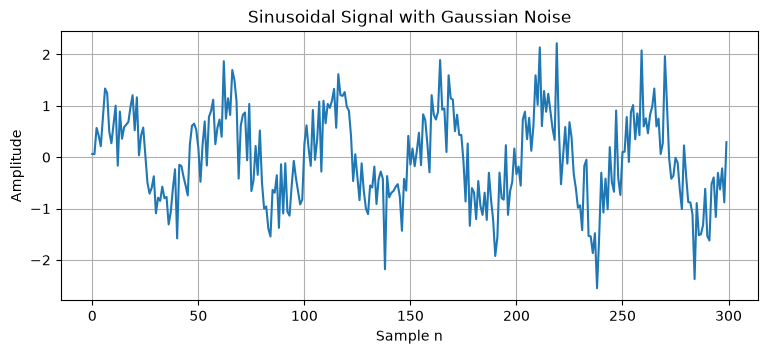

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

rng = np.random.default_rng(0)

n = np.arange(300)
x = np.sin(2 * np.pi * n / 50) + 0.5 * rng.standard_normal(300)

plt.figure()
plt.plot(n, x)
plt.title("Sinusoidal Signal with Gaussian Noise")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

M_values = [3, 9, 25]
smoothed_signals = {}

for M in M_values:
    h = np.ones(M) / M
    smoothed_signals[M] = np.convolve(x, h, mode="same")

    print(f"Moving-average filter M = {M} completed.")

Moving-average filter M = 3 completed.
Moving-average filter M = 9 completed.
Moving-average filter M = 25 completed.


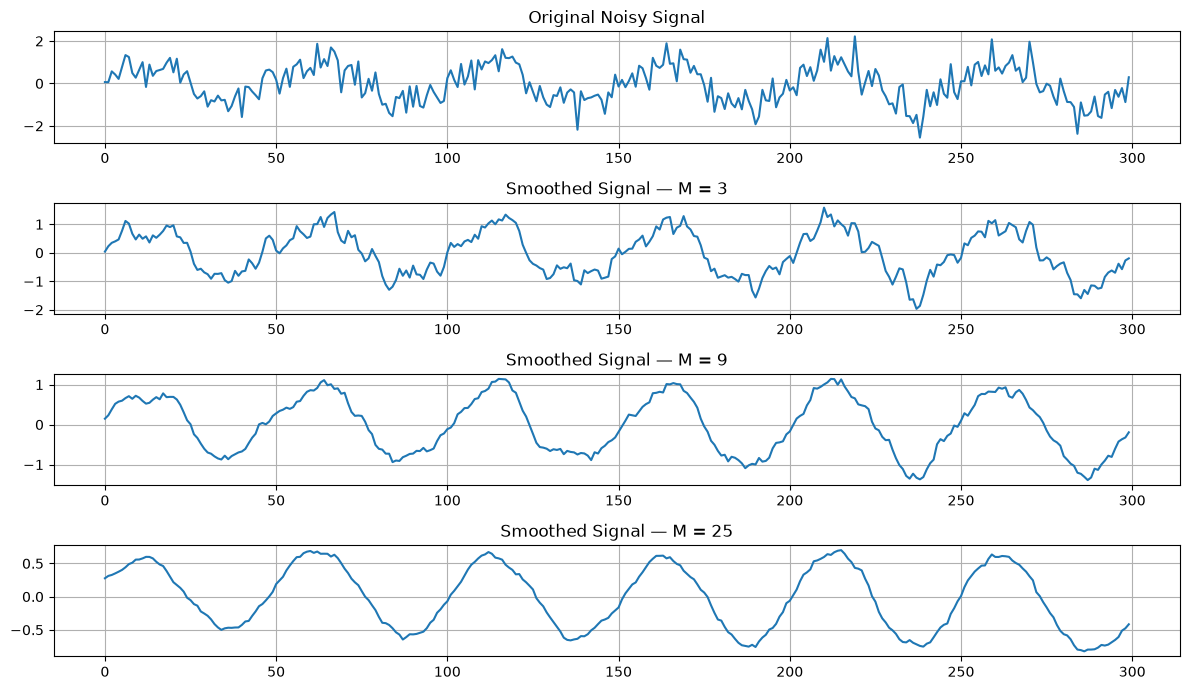

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

plt.figure(figsize=(12, 7))

plt.subplot(4, 1, 1)
plt.plot(n, x)
plt.title("Original Noisy Signal")
plt.grid()

for i, M in enumerate(M_values, start=2):
    plt.subplot(4, 1, i)
    plt.plot(n, smoothed_signals[M])
    plt.title(f"Smoothed Signal — M = {M}")
    plt.grid()

plt.tight_layout()
plt.show()

### Observations

- M = 3: Provides light smoothing while preserving most of the original signal's shape.
- M = 9: Reduces more noise while retaining the general sinusoidal waveform.
- M = 25: Provides stronger smoothing but causes greater distortion and attenuation of the signal's peaks.

Increasing the moving-average window length improves noise suppression but also removes more signal detail.

## Task 3.3 — Testing Linearity and Time-Invariance

Test three systems:

1. y(n) = x²(n)
2. y(n) = n x(n)
3. A three-point moving-average filter

A system is linear if it satisfies superposition. It is time-invariant if delaying the input produces an equally delayed output.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

a = 2.0
b = -3.0

systems = {
    "x^2": lambda x: x**2,
    "n*x(n)": lambda x: np.arange(len(x)) * x,
    "Moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

for name, T in systems.items():

    # Test linearity
    left_side = T(a*x1 + b*x2)
    right_side = a*T(x1) + b*T(x2)

    linear = np.allclose(left_side, right_side)

    # Test time-invariance using a delay of 5 samples
    xd = np.concatenate([np.zeros(5), x1])[:50]

    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    time_invariant = np.allclose(T(xd), yd)

    print(f"System: {name}")
    print(f"Linear: {linear}")
    print(f"Time-invariant: {time_invariant}")
    print("-" * 35)

System: x^2
Linear: False
Time-invariant: True
-----------------------------------
System: n*x(n)
Linear: True
Time-invariant: False
-----------------------------------
System: Moving average
Linear: True
Time-invariant: True
-----------------------------------


### Interpretation

1. **System y(n) = x²(n):** Nonlinear because squaring the input does not satisfy the superposition principle. It is time-invariant because the operation does not explicitly depend on n.

2. **System y(n) = n x(n):** Linear because it satisfies superposition. It is time-varying because its output depends explicitly on the time index n.

3. **Three-point moving average:** Linear and time-invariant because it is a convolution with a fixed impulse response.

Therefore, the moving-average system is the only LTI system among the three tested systems.

## Task 3.4 — Estimating Time Delay Using Cross-Correlation

Cross-correlation measures the similarity between two signals at different relative time shifts. The location of its maximum value can be used to estimate the delay between a transmitted signal and a received signal.

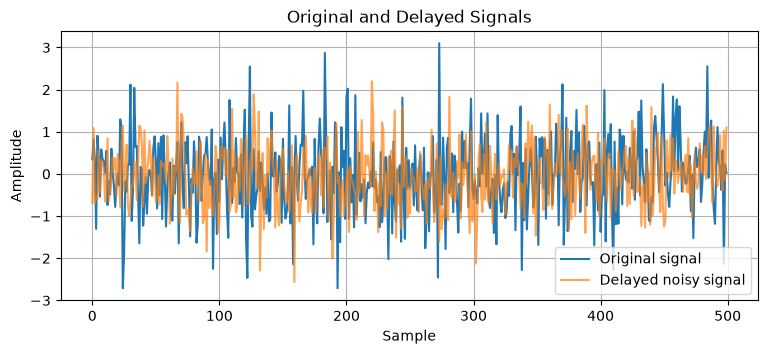

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

true_delay = 37

y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]
y = y + 0.5*rng.standard_normal(500)

plt.figure()
plt.plot(x, label="Original signal")
plt.plot(y, label="Delayed noisy signal", alpha=0.7)
plt.title("Original and Delayed Signals")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

Actual delay: 37 samples
Estimated delay: 37 samples
Estimated delay in seconds: 0.037


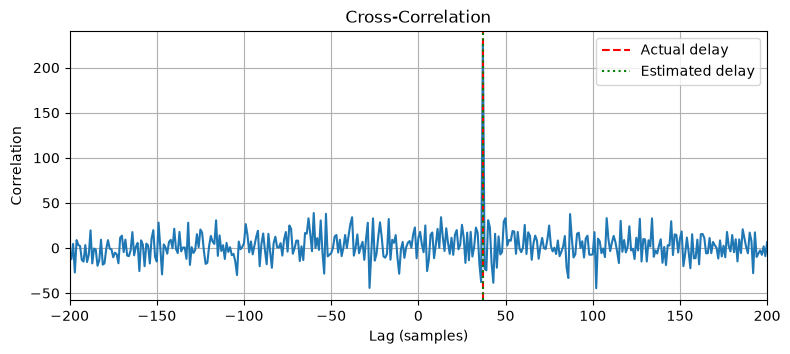

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")

estimated_delay = lags[np.argmax(r)]

print("Actual delay:", true_delay, "samples")
print("Estimated delay:", estimated_delay, "samples")
print("Estimated delay in seconds:", estimated_delay/fs)

plt.figure()
plt.plot(lags, r)
plt.axvline(true_delay, color="red", linestyle="--",
            label="Actual delay")
plt.axvline(estimated_delay, color="green", linestyle=":",
            label="Estimated delay")
plt.xlim(-200, 200)
plt.title("Cross-Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.legend()
plt.grid()
plt.show()

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

noise_levels = [0.5, 1.0, 2.0, 4.0]

for noise_level in noise_levels:
    rng = np.random.default_rng(1)

    noisy_y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]
    noisy_y += noise_level*rng.standard_normal(500)

    correlation = signal.correlate(noisy_y, x, mode="full")
    lag_values = signal.correlation_lags(
        len(noisy_y), len(x), mode="full"
    )

    estimate = lag_values[np.argmax(correlation)]

    print(
        f"Noise standard deviation: {noise_level:.1f} | "
        f"Estimated delay: {estimate} samples"
    )

Noise standard deviation: 0.5 | Estimated delay: 37 samples
Noise standard deviation: 1.0 | Estimated delay: 0 samples
Noise standard deviation: 2.0 | Estimated delay: 0 samples
Noise standard deviation: 4.0 | Estimated delay: 0 samples


### Engineering Application

Cross-correlation can be used in acoustic distance measurement and leak detection in water pipelines.

For example, sensors placed at different positions along a water pipe can detect the sound produced by a leak. Comparing the recorded signals helps estimate the time difference between their arrivals. This information can be used to locate the leak.

For a sound travelling at approximately 343 m/s, the one-way distance travelled during a delay is:

distance = speed × time

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

speed_of_sound = 343
time_delay = estimated_delay / fs
distance = speed_of_sound * time_delay

print(f"Estimated time delay: {time_delay:.4f} seconds")
print(f"Estimated one-way distance: {distance:.2f} metres")

Estimated time delay: 0.0370 seconds
Estimated one-way distance: 12.69 metres


## Task 3.5 — Solving a Difference Equation

Consider the difference equation:

y(n) - 0.75y(n-1) + 0.125y(n-2) = x(n) + x(n-1)

We will calculate its impulse response using direct recursion, verify it using scipy.signal.lfilter, and compare both results with the theoretical expression:

h(n) = 6(0.5)^n - 5(0.25)^n

Impulse response using recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


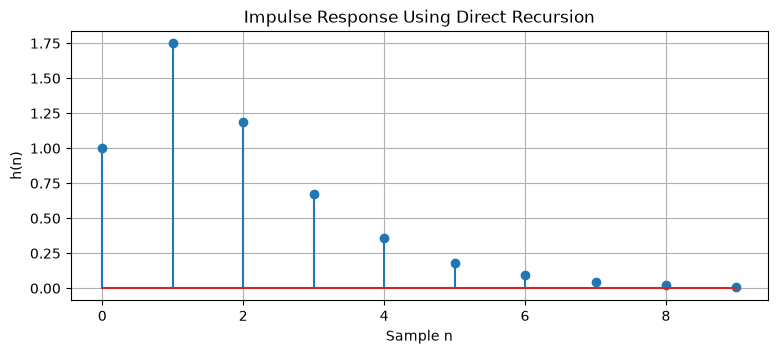

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

N = 10
x_impulse = np.zeros(N)
x_impulse[0] = 1

h_recursion = np.zeros(N)

for n in range(N):
    x_previous = x_impulse[n-1] if n >= 1 else 0
    y_previous = h_recursion[n-1] if n >= 1 else 0
    y_previous2 = h_recursion[n-2] if n >= 2 else 0

    h_recursion[n] = (
        x_impulse[n] + x_previous
        + 0.75*y_previous - 0.125*y_previous2
    )

print("Impulse response using recursion:")
print(h_recursion)

plt.figure()
plt.stem(np.arange(N), h_recursion)
plt.title("Impulse Response Using Direct Recursion")
plt.xlabel("Sample n")
plt.ylabel("h(n)")
plt.grid()
plt.show()

Recursion: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Theoretical: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Recursion and lfilter match: True
lfilter and theoretical results match: True


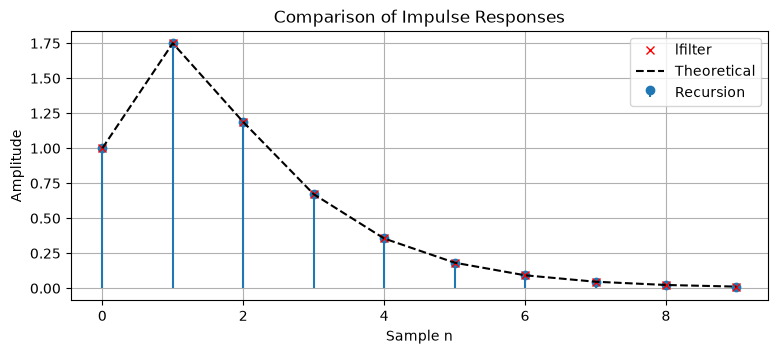

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

b = [1, 1]
a = [1, -0.75, 0.125]

h_lfilter = signal.lfilter(b, a, x_impulse)

n = np.arange(N)
h_theoretical = 6*(0.5**n) - 5*(0.25**n)

print("Recursion:", h_recursion)
print("lfilter:", h_lfilter)
print("Theoretical:", h_theoretical)

print("Recursion and lfilter match:",
      np.allclose(h_recursion, h_lfilter))

print("lfilter and theoretical results match:",
      np.allclose(h_lfilter, h_theoretical))

plt.figure()
plt.stem(n, h_recursion, linefmt="C0-", markerfmt="C0o",
         basefmt=" ", label="Recursion")
plt.plot(n, h_lfilter, "rx", label="lfilter")
plt.plot(n, h_theoretical, "k--", label="Theoretical")
plt.title("Comparison of Impulse Responses")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

Step response:
[1.         2.75       3.9375     4.609375   4.96484375 5.14746094
 5.23999023 5.28656006 5.30992126 5.32162094]
Theoretical final value H(1): 5.333333
Last calculated sample: 5.321621


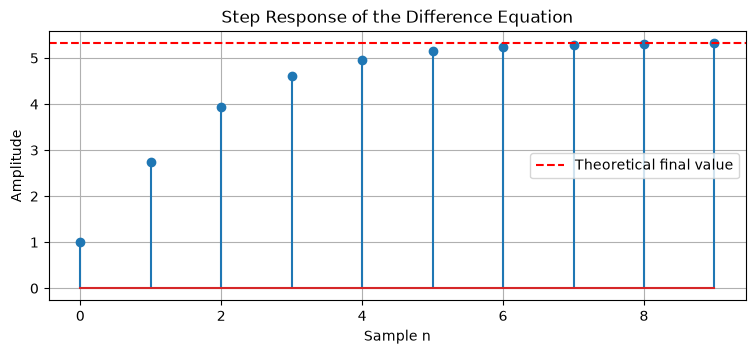

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

step_input = np.ones(N)
step_response = signal.lfilter(b, a, step_input)

theoretical_final_value = sum(b) / sum(a)

print("Step response:")
print(step_response)
print(f"Theoretical final value H(1): {theoretical_final_value:.6f}")
print(f"Last calculated sample: {step_response[-1]:.6f}")

plt.figure()
plt.stem(np.arange(N), step_response)
plt.axhline(theoretical_final_value, color="red",
            linestyle="--", label="Theoretical final value")
plt.title("Step Response of the Difference Equation")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

### Observations

- The impulse responses calculated by direct recursion, `lfilter`, and the theoretical expression should agree.
- The impulse response decays over time because both poles are inside the unit circle.
- The step response approaches the theoretical steady-state value H(1).
- The system is an IIR system because its impulse response continues indefinitely, although its values decay towards zero.

## Week 3 — Analysis Questions

### Question 1
Why is `np.convolve()` much faster than the manually implemented convolution function?

**Answer:**

The manual implementation uses nested loops to calculate every multiplication and addition individually. For sequences of lengths L and M, direct convolution requires approximately L × M multiplication-accumulation operations.

NumPy uses optimized, compiled numerical routines rather than executing the operations through Python loops. This reduces execution overhead and makes it significantly faster.

### Question 2
Which systems in Task 3.3 are LTI? Explain.

**Answer:**

Only the three-point moving-average system is both linear and time-invariant.

- The squaring system is nonlinear but time-invariant.
- The system y(n) = n x(n) is linear but time-varying.
- The moving-average system is linear and time-invariant because it uses a fixed impulse response.

### Question 3
Give two engineering applications of cross-correlation in Tanzania.

**Answer:**

1. **Water pipeline leak detection:** Sensors installed along water pipelines can compare acoustic signals to estimate the location of leaks.
2. **GPS positioning:** GPS receivers use correlation between locally generated codes and received satellite signals to determine signal arrival times and estimate position.

### Question 4
Is the system in Task 3.5 FIR or IIR? Is it stable?

**Answer:**

The system is an Infinite Impulse Response (IIR) system because its feedback terms depend on previous output samples.

The system is stable because its poles are 0.5 and 0.25, both of which lie inside the unit circle. Its impulse response decays towards zero, satisfying the absolute-summability condition for BIBO stability.

## AI-Use Statement

AI tools used: ChatGPT.

Used for: Understanding laboratory instructions, explaining DSP concepts, and receiving guidance on Python code implementation.

How I verified the output: I executed the code cells in JupyterLab and checked the numerical results, plots, convolution outputs, delay estimates, and impulse responses.

I confirm that I understand and can explain all submitted code.